# Simple Linear Regression 

In this example we will consider sales based on 'TV' marketing budget. 

In this notebook, we'll build a linear regression model to predict 'Sales' using 'TV Ads budget' as the predictor variable.

TV: Advertising budget spent on TV (in thousands of dollars)

Sales: Product sales in units (in thousands)

## Understanding the Data

Let's start with the following steps:

1. Importing data using the pandas library
2. Understanding the structure of the data

In [1]:
import pandas as pd
import numpy as np

In [2]:
advertising = pd.read_csv("tvmarketing.csv")

Now, let's check the structure of the advertising dataset.

In [3]:
# Display the first 5 rows
advertising.head()

,TV,Sales
0,230.1,22.1
1,44.5,10.4
2,17.2,9.3
3,151.5,18.5
4,180.8,12.9


In [4]:
# Display the last 5 rows
advertising.tail()

,TV,Sales
195,38.2,7.6
196,94.2,9.7
197,177.0,12.8
198,283.6,25.5
199,232.1,13.4


In [5]:
# Let's check the columns in the given dataset.
advertising.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   TV      200 non-null    float64
 1   Sales   200 non-null    float64
dtypes: float64(2)
memory usage: 3.2 KB


In [6]:
# Check the shape of the DataFrame (rows, columns)
advertising.shape

(200, 2)

In [7]:
#finding co-relation
advertising.corr()

,TV,Sales
TV,1.000000,0.782224
Sales,0.782224,1.000000


In [8]:
# Let's look at some statistical information about the dataframe.
advertising.describe()

,TV,Sales
count,200.000000,200.000000
mean,147.042500,14.022500
std,85.854236,5.217457
min,0.700000,1.600000
25%,74.375000,10.375000
50%,149.750000,12.900000
75%,218.825000,17.400000
max,296.400000,27.000000


# Visualising Data Using Seaborn

In [9]:
# Conventional way to import seaborn
import seaborn as sns

# To visualise in the notebook
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

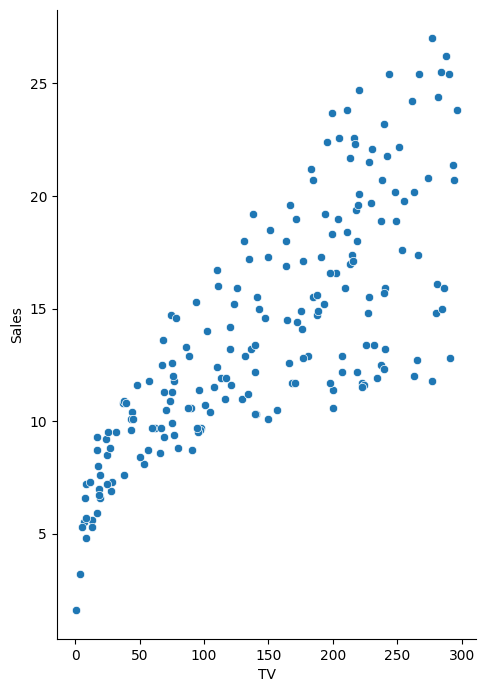

In [10]:
# Visualise the relationship between the features and the response using scatterplots
sns.pairplot(advertising, x_vars=['TV'], y_vars=['Sales'],size=7, aspect=0.7, kind='scatter')

# Performing Simple Linear Regression

Equation of linear regression<br>
$y = c + m_1x_1 + m_2x_2 + ... + m_nx_n$

-  $y$ is the response
-  $c$ is the intercept
-  $m_1$ is the coefficient for the first feature
-  $m_n$ is the coefficient for the nth feature<br>

In our case:

$y = c + m_1 \times TV$

The $m$ values are called the model **coefficients** or **model parameters**.

### Generic Steps in Model Building using ```sklearn```

Before you read further, it is good to understand the generic structure of modeling using the scikit-learn library. Broadly, the steps to build any model can be divided as follows: 

## Preparing X and y

-  The scikit-learn library expects X (feature variable) and y (response variable) to be NumPy arrays.
-  However, X can be a dataframe as Pandas is built over NumPy.

In [11]:
advertising.head()

,TV,Sales
0,230.1,22.1
1,44.5,10.4
2,17.2,9.3
3,151.5,18.5
4,180.8,12.9


In [12]:
# Putting feature variable to X
X = advertising['TV']

# Print the first 5 rows
X.head()

0    230.1
1     44.5
2     17.2
3    151.5
4    180.8
Name: TV, dtype: float64

In [13]:
# Putting response variable to y
y = advertising['Sales']

# Print the first 5 rows
y.head()

0    22.1
1    10.4
2     9.3
3    18.5
4    12.9
Name: Sales, dtype: float64

## Splitting Data into Training and Testing Sets

In [14]:
#random_state is the seed used by the random number generator, it can be any integer.
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7)

In [15]:
X_train[:5]

149     44.7
70     199.1
93     250.9
65      69.0
113    209.6
Name: TV, dtype: float64

In [16]:
y_train[:5]

149    10.1
70     18.3
93     22.2
65      9.3
113    15.9
Name: Sales, dtype: float64

In [17]:
X_test[:5]

59    210.7
99    135.2
42    293.6
24     62.3
25    262.9
Name: TV, dtype: float64

In [18]:
y_test[:5]

59    18.4
99    17.2
42    20.7
24     9.7
25    12.0
Name: Sales, dtype: float64

In [19]:
len(X_train)

140

In [20]:
len(y_test)

60

In [21]:
print(type(X_train))
print(type(X_test))
print(type(y_train))
print(type(y_test))

<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>
<class 'pandas.core.series.Series'>


In [22]:
X_train[:5]

149     44.7
70     199.1
93     250.9
65      69.0
113    209.6
Name: TV, dtype: float64

In [23]:
X_train.head()

149     44.7
70     199.1
93     250.9
65      69.0
113    209.6
Name: TV, dtype: float64

In [24]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(140,)
(140,)
(60,)
(60,)


In [25]:
X_train.ndim

1

In [26]:
X_train

149     44.7
70     199.1
93     250.9
65      69.0
113    209.6
       ...  
69     216.8
138     43.0
126      7.8
132      8.4
192     17.2
Name: TV, Length: 140, dtype: float64

In [ ]:
X_train = np.reshape(X_train,(-1,1))
X_test = np.reshape(X_test,(-1,1))


In [28]:
X_train.shape

(140, 1)

In [65]:
X_test.shape

(60, 1)

In [29]:
X_train

array([[ 44.7],
       [199.1],
       [250.9],
       [ 69. ],
       [209.6],
       [214.7],
       [ 38.2],
       [266.9],
       [232.1],
       [112.9],
       [284.3],
       [117.2],
       [ 17.9],
       [287.6],
       [182.6],
       [137.9],
       [217.7],
       [131.1],
       [193.7],
       [222.4],
       [262.7],
       [ 74.7],
       [188.4],
       [237.4],
       [228.3],
       [ 80.2],
       [ 67.8],
       [ 48.3],
       [151.5],
       [  8.6],
       [280.2],
       [129.4],
       [ 11.7],
       [ 76.3],
       [239.3],
       [120.5],
       [255.4],
       [296.4],
       [239.9],
       [  4.1],
       [289.7],
       [ 16.9],
       [227.2],
       [213.5],
       [241.7],
       [170.2],
       [ 75.5],
       [218.5],
       [110.7],
       [ 94.2],
       [ 50. ],
       [265.2],
       [243.2],
       [  5.4],
       [ 17.2],
       [ 70.6],
       [273.7],
       [229.5],
       [ 25.6],
       [184.9],
       [ 13.1],
       [107.4],
       [

In [30]:
X_train.ndim

2

In [31]:
# #It is a general convention in scikit-learn that observations are rows, while features are columns. 
# #This is needed only when you are using a single feature; in this case, 'TV'.

# import numpy as np

# X_train = X_train[:, np.newaxis]
# X_test = X_test[:, np.newaxis]

In [32]:
print(X_train.shape)
print(y_train.shape)
print(X_test.shape)
print(y_test.shape)

(140, 1)
(140,)
(60, 1)
(60,)


In [33]:
X_train.ndim

2

In [34]:
X_train[:5]

array([[ 44.7],
       [199.1],
       [250.9],
       [ 69. ],
       [209.6]])

In [35]:
y_train[:5]

149    10.1
70     18.3
93     22.2
65      9.3
113    15.9
Name: Sales, dtype: float64

## Performing Linear Regression

In [36]:
# import LinearRegression from sklearn
from sklearn.linear_model import LinearRegression

# Representing LinearRegression as lr(Creating LinearRegression Object)
lr = LinearRegression()


# Fit the model using lr.fit()
lr.fit(X_train, y_train) #model training

LinearRegression()

## Having a look at the coefficients that the model has chosen:

In [37]:
# Print the intercept and coefficients
print(lr.intercept_)
print(lr.coef_)

6.738938739213808
[0.0503962]


$y = 0.045 \times TV $ + 7.029

**The formula estimates that for each increase of 1 dollar in tv
advertising costs, the expected sales are to increase by 0.0464**


The value of c is approximately 6.98

This illustrates that your model predicts the response 6.98 when 𝑥 is zero.

**The value m = 0.04 means that the predicted response rises by 0.04 when 𝑥 is increased by 1 unit.**


Now, let's use this equation to predict our sales.

## Predictions
We can use model  for predictions with either existing or new data. To obtain the predicted response, use .predict():

In [38]:
# Making predictions on the testing set
y_pred = lr.predict(X_test)

In [39]:
y_pred.shape

(60,)

In [40]:
#predicted values
y_pred[:5]

array([17.35741785, 13.55250483, 21.53526275,  9.87862193, 19.98809944])

In [41]:
# existing data y_test
y_test[:5]

59    18.4
99    17.2
42    20.7
24     9.7
25    12.0
Name: Sales, dtype: float64

In [42]:
#lets predict y when tvadv= 44.5
sales_predicted = lr.predict([[44.5]])

In [43]:
sales_predicted

array([8.98156959])

In [44]:
lr

LinearRegression()

#### Show Actual and Predicted values

Text(0, 0.5, 'Sales')

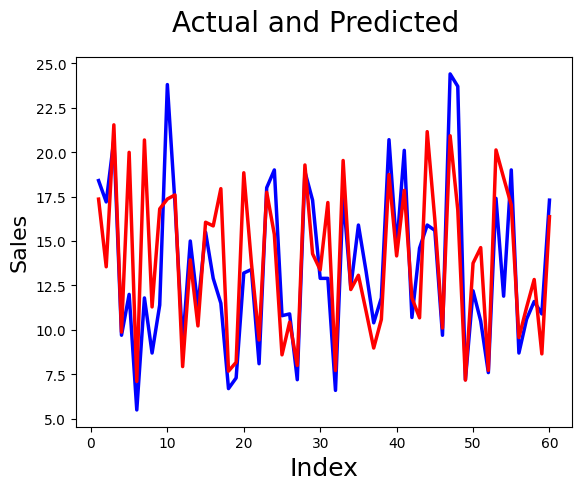

In [45]:
# Actual vs Predicted
import matplotlib.pyplot as plt
c = [i for i in range(1,61,1)]         # generating index 
fig = plt.figure()
plt.plot(c,y_test, color="blue", linewidth=2.5, linestyle="-")
plt.plot(c,y_pred, color="red",  linewidth=2.5, linestyle="-")
fig.suptitle('Actual and Predicted', fontsize=20)              # Plot heading 
plt.xlabel('Index', fontsize=18)                               # X-label
plt.ylabel('Sales', fontsize=16)                       # Y-label

Text(0, 0.5, 'ytest-ypred')

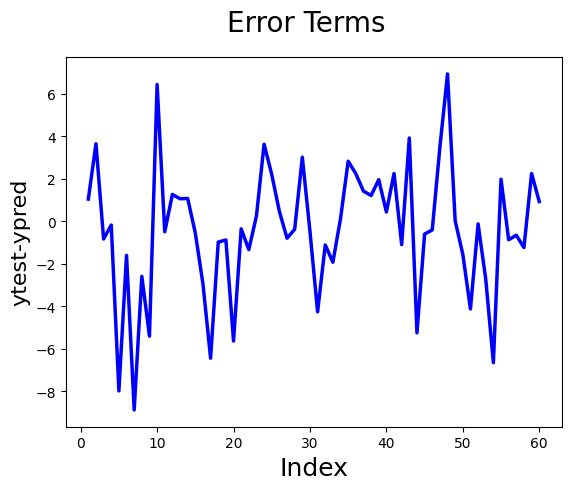

In [46]:
# Error terms
c = [i for i in range(1,61,1)]
fig = plt.figure()
plt.plot(c,y_test-y_pred, color="blue", linewidth=2.5, linestyle="-")
fig.suptitle('Error Terms', fontsize=20)              # Plot heading 
plt.xlabel('Index', fontsize=18)                      # X-label
plt.ylabel('ytest-ypred', fontsize=16)                # Y-label

## Regression Evaluation Metrics
### Cost/loss function-

Here are three common evaluation metrics for regression problems:

**Mean Absolute Error** (MAE) is the mean of the absolute value of the errors:

$$\frac 1n\sum_{i=1}^n|y_i-\hat{y}_i|$$

**Mean Squared Error** (MSE) is the mean of the squared errors:

$$\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2$$

**Root Mean Squared Error** (RMSE) is the square root of the mean of the squared errors:

$$\sqrt{\frac 1n\sum_{i=1}^n(y_i-\hat{y}_i)^2}$$

Comparing these metrics:

- **MAE** is the easiest to understand, because it's the average error.
- **MSE** is more popular than MAE, because MSE "punishes" larger errors, which tends to be useful in the real world.
- **RMSE** is even more popular than MSE, because RMSE is interpretable in the "y" units.

All of these are **loss functions**, because we want to minimize them.

 MAE – Mean Absolute Error ∣
It calculates the average of the absolute differences between actual values and predicted values.

Interpretation: “On average, our model is off by X units.”

✅ Pros: Easy to understand.

❌ Cons: Doesn’t penalize large errors as heavily.

MSE – Mean Squared Error

Like MAE, but squares the errors before averaging.

This means large errors get more weight, which is useful if we want to be strict about big mistakes.

✅ Pros: Penalizes big errors.

❌ Cons: Squared units — not as interpretable as the original units of y.

RMSE – Root Mean Squared Error

Just the square root of MSE.

This makes the error metric go back to the original units of y, which makes it easier to interpret.

✅ Pros: Combines the benefits of MSE (penalizing big errors) and being interpretable like MAE.

❌ Cons: Slightly more complex.



In [ ]:
#Evaluation of regresion 

from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)
mse


9.897261071606069

### Model Performance - R2 score

Coefficient of determination also called as R2 score is used to evaluate the performance
of a linear regression model.

It is the amount of the variation in the output (dependent attribute)
which is predictable from the input (independent variable(s)). 

It is used to check how well-observed results are reproduced by the model, depending
on the ratio of total deviation of results described by the model.

Mathematical Formula:

R2= 1- SSres / SStot

Where,
SSres is the sum of squares of the residual errors.

SStot is the total sum of the errors.

<b>Interpretation of R2 score:</b>

Assume R2 = 0.62

It can be referred that 62% of the changeability of the dependent output attribute

can be explained by the model while the remaining 38 % of the variability is still unaccounted for.

R2 indicates the proportion of data points which lie within the line created by the regression equation.

<b>A higher value of R2 is desirable as it indicates better results.</b>

In [ ]:
# R-square:
# 1)Measures how well our models predictions match with our actual data.
# 2)Its a percentage between(0 - 100%) which tells us how much of the variability
# in the target(dependent) variable is explained by our model.

# eg: trying to predict friends expense based on his salary
# #Limitation:   
# 1)when you add more predictors to your model , your r2 will generally increase,
# weather or not the predictors are truly meaning full or impactfull.
# 2)This means a model with more variables might seem better just bcoz it has more variables,
# not bcoz its a better fit for the data. 

# r2= 1- rss/tss

# rss(residual sum of square) = diff between actual and predicted values
# tss(total sum of square) = diff between actual and mean of actual values


In [49]:
#adjusted r-square:

# 1)Adjusted rquare adjusts the rsquare values based on the number of predictors in the model.
# 2)it increases only if the new predictor improves the model.
# 3)it will decrease if the predictor improves the model less than predicted.

# eg: trying to predict friends expense based on his salary
# lets say we add more predictos like "no of vacation takes" or "shoe size".
# while "no of vacation takes" might have some relation to spending but "shoe size" not likely.
# adjusted r-square will penalize for adding irrelavant predictors like "shoe size"

# Why its better:Gives you more realistic picture of how well the model performs to new data,
# especially when you have too many predictors
# it penalized ur model complexity ,so we are encouraged to keep only the meangifull ones.

# adjusted r-square= 1-(1-r2) * (n-1)/(n-p-1)
# n= no of observatios
# p= no of predictors

In [50]:
# #inshort summary: R2 tells you how well your model fits the data
# Adjusted R2 gives you a very clear pcitures of its goodnes of fit when you have many predictors
# it esnures u are not just adding  var for the sake  of making ur model look better.

http://media.geeksforgeeks.org/wp-content/uploads/20200603172827/img159.png

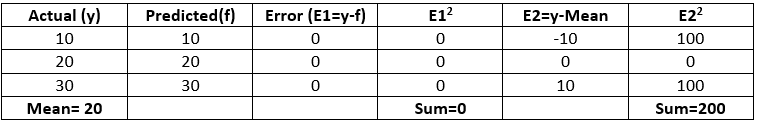

In [51]:
from IPython import display
display.Image("img159.png")

R2 = 1- 0/200 = 1

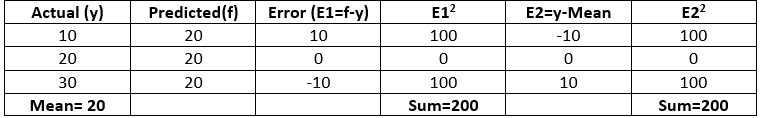

In [52]:
from IPython import display
display.Image("img248.png")

R2 = 1- 200/200 = 0

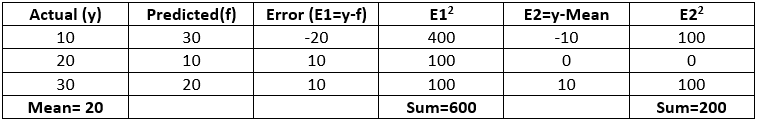

In [53]:
from IPython import display
display.Image("img331.png")

R2 = 1- 600/200 = -2

#We can import r2_score from sklearn.metrics in Python to compute R2 score.



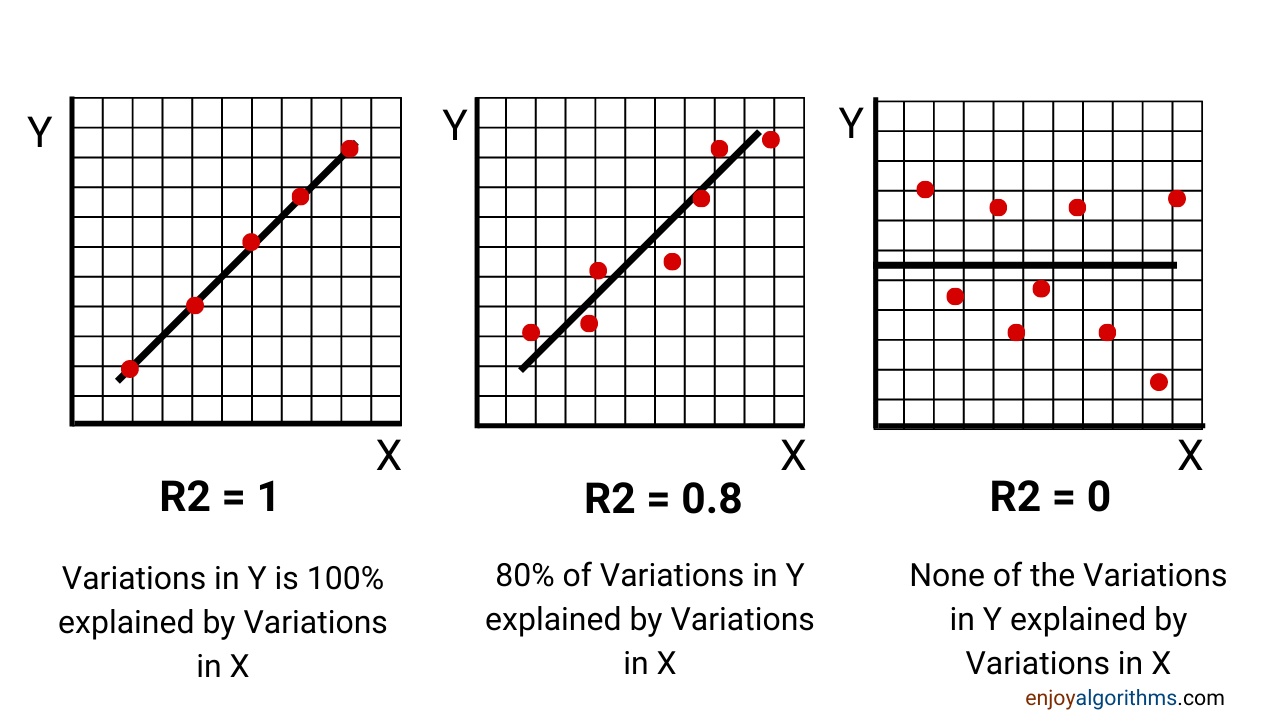

In [54]:
from IPython import display
display.Image("1_oQVxk-Eb5lyOrsidK12umQ.png")

In [55]:
from sklearn.metrics import r2_score

### Assume y is the actual value and y_pred is the predicted values
# y =[10, 20, 30]
# y_pred =[10, 20, 30]
# r2 = r2_score(y, y_pred)
# print('r2 score for perfect model is', r2)

In [56]:
### Assume y is the actual value and f is the predicted values
# y =[10, 20, 30]
# y_pred =[20, 20, 20]
# r2 = r2_score(y, y_pred)
# print('r2 score for a model which predicts mean value always is', r2)

In [57]:
### Assume y is the actual value and f is the predicted values
# y = [10, 20, 30]
# y_pred = [30, 10, 20]
# r2 = r2_score(y, y_pred)
# print('r2 score for a worse model is', r2)

The best possible score is 1 which is obtained when the predicted values are the same as the actual values.

R2 score of baseline model is 0.

During the worse cases, R2 score can even be negative.

### Computing RMSE and R^2 Values

In [58]:
from sklearn.metrics import r2_score

# R2 for above usecase

r_squared = r2_score(y_test, y_pred)

In [59]:
print('r_square_value :',r_squared)

r_square_value : 0.5220853914862877


In [60]:
from sklearn import metrics
print('MAE:', metrics.mean_absolute_error(y_test, y_pred))
print('MSE:', metrics.mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

MAE: 2.2915574534767846
MSE: 9.897261071606069
RMSE: 3.1459912701096404


Text(0, 0.5, 'Predicted Y')

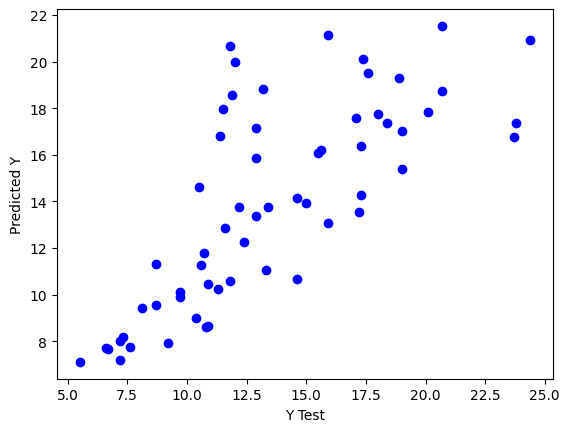

In [61]:
import matplotlib.pyplot as plt

plt.scatter(y_test,y_pred,color=["blue"])
plt.xlabel('Y Test')
plt.ylabel('Predicted Y')

In [62]:
# Seeing the Best fit line

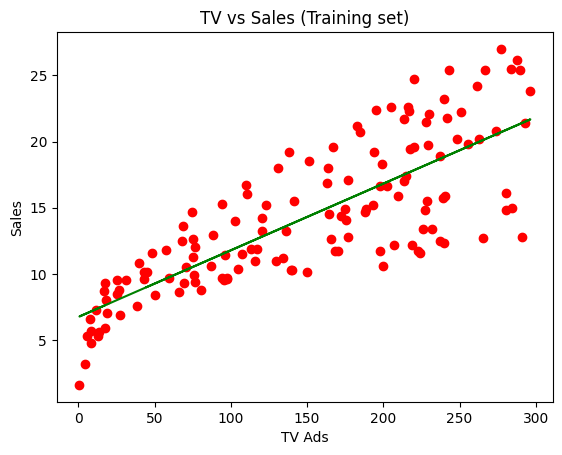

In [63]:
plt.scatter(X_train, y_train, color = "red")
plt.plot(X_train, lr.predict(X_train), color = "green")
plt.title("TV vs Sales (Training set)")
plt.xlabel("TV Ads")
plt.ylabel("Sales")
plt.show()

In [64]:
# The End....